# 104_05 — PSBPM-FD con cuatro predictores y tres intervalos contra FAR y RF · Santiago (Parque O'Higgins) horario · PM2.5 (log) · rezago 1 cruzado · $M = 1..6$

**La 104 es la 28 bajo un ID nuevo** (`real_pm25_104_v02`, copiada con `00_copiar_28.py`; trazas de la 28): la esperanza, la equi-colas, el FAR y el RF deben reproducir la 28 al bit. El `300_05` sobre lo que persiste `104_04`: una fila por predictor en el Bloque A, una banda por construcción en el Bloque B (`111_*` contra el FAR), §9 sobre la ventana de detalle y §10 sobre todo el test y la ventana de detalle. Competidores: FAR(1) y RF con el rezago 1 de los $M$ scores, las covariables del PSBPM-FD. Cálculo en `fit/comparacion_barrido.py`, figuras en `graphics/viz_comparacion.py`.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
import json

import numpy as np

from model_psbp_fd.fit.convergencia_barrido import cargar_artefactos
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB, cargar_representaciones, serie_origenes,
)
from model_psbp_fd.fit.comparacion_barrido import (
    G_FAR, G_PSG, G_PSB, PISO,
    preparar_diseno, ajustar_far, ajustar_rf, cargar_psbp,
    tablas_modelos, verificar_cadena_modelos,
    construir_bandas, tabla_bloque_B, ventana_bloque_B,
    ganadores_por_ventana, resumen_min_max, promedio_vs_M,
    origenes_extremos, contraste_origenes, nombre_psbp, validar_comportamientos_barrido,
    G_PSS, G_PSH, bloqueB_contra_far,
)
from model_psbp_fd.fit.evaluacion_barrido import INTERVALOS as INTERVALOS_TODOS
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.graphics import (
    plot_ventana_movil, ESTILOS_MODELOS, ESTILOS_MODELOS_PREDICTORES, plot_validacion_observado,
    plot_ganador_modelo, plot_metricas_vs_M, plot_bandas_contraste,
)
from model_psbp_fd.fit.comportamientos import cargar_comportamientos, validar_observado
from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 104_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "pm25_104", 2   # ventana 2: entrena 2015-2022, prueba 2023-2025 (28_01 §1.1; artefactos copiados por 00_copiar_28.py)
M_FPCA_LIST = (1, 2, 3, 4, 5, 6)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la comparación. Ventanas, nivel y objetivo se LEEN de eval_config.json
# (artefacto de 104_01): no se redeclaran aquí.
PESOS_TAU = None          # cuadratura trapezoidal por defecto
PREFIJO   = 70            # este notebook escribe 70-83 en cada M y 96-99, 105-107, 111 en el barrido
INTERVALOS  = INTERVALOS_TODOS    # equicolas, simultanea, hdr: una banda del PSBPM-FD por construcción
N_DETALLE   = 10        # orígenes consecutivos de prueba para el análisis predictivo (§9, §10)
T0_DETALLE  = None      # el _05 LEE la ventana del _04 (112_ventana_detalle.json); un entero sólo la verifica
PREDICTORES = PREDICTORES_TODOS   # una fila del PSBPM-FD por predictor puntual (104_04 §3)

# FAR (§3.1): FAR(1), p = N_LAGS = 1 fijo, como en la 28. Tope del barrido de kn
# (acota en K = 10, no en L) y criterio de far.cv.
KN_MAX      = 12
CRITERIO_KN = "L2"

# Random Forest (§3.2): hiperparámetros fijos entre escenarios y entre puntos del barrido.
SEED_ML   = 20260830
PARAMS_RF = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                 random_state=SEED_ML, n_jobs=-1)

# Bloque B (§5): FAR con banda gaussiana de residuos de train y PSBPM-FD con su banda
# nativa (cuantiles de su predictiva).
IC_POR_TAU                = True    # sigma_eps(tau) punto a punto (False = ancho constante)
IC_CORRECCION_ESTIMACION  = True    # infla sigma por sqrt(1 + kn/n_train)
IC_PSBP_TAMBIEN_GAUSSIANA = False   # control opcional: no se corre (sólo FAR gaussiano y PSBPM-FD nativo)

# §9: por qué métrica se eligen los orígenes extremos, cuántos, qué dos bandas se
# contrastan (prefijos, en orden) y en qué M (None = todos).
METRICA_SEL_IC     = "rmse_f"     # una de METRICAS_A_COLS
N_EXTREMOS         = 5
BANDA_A_CONTRASTAR = ("FAR", "PSBPM-FD (predictiva")
M_DETALLE          = None

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]
assert METRICA_SEL_IC in METRICAS_A_COLS[:3], "METRICA_SEL_IC: mae_f, rmse_f o linf_medio."

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 96-99, 105-107)")

# Ancho de referencia del documento: None = el de siempre (el del medio, 30; decisión 2026-10-12, para no
# reejecutar el _04). Un entero de VENTANAS_W sobrescribe DIS["W_REF"] sin tocar eval_config.json.
W_REF_DOC = None


EXPERIMENT_BASE : real_pm25_104_v02
barrido en M    : [1, 2, 3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_pm25_104_v02_barrido_M   (archivos 96-99, 105-107)


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS  = cargar_representaciones(EST)
ORIG = serie_origenes(DIS)

T0, N_LAGS, NIVEL = DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W = DIS["VENTANAS_W"]
if W_REF_DOC is not None:
    assert int(W_REF_DOC) in VENTANAS_W, f"W_REF_DOC={W_REF_DOC} no está en {VENTANAS_W}"
    DIS["W_REF"] = int(W_REF_DOC)
W_REF = DIS["W_REF"]
print(f"ancho de referencia de este notebook: w = {W_REF}" + ("  (W_REF_DOC)" if W_REF_DOC is not None else ""))
grilla, X_obj_ev  = DIS["grilla"], ORIG["X_obj_ev"]
t_orig, es_train  = ORIG["t_orig"], ORIG["es_train"]

  M  comp  cadenas  covariables  seed_base
  1     1        1            1  41232
  2     2        1            2  41232
  3     3        1            3  41232
  4     4        1            4  41232
  5     5        1            5  41232
  6     6        1            6  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)
M=1  FPCA M=1 K=10  var. explicada=76.6746%  ·  curvas (4018, 24)
M=2  FPCA M=2 K=10  var. explicada=86.3636%  ·  curvas (4018, 24)
M=3  FPCA M=3 K=10  var. explicada=91.9030%  ·  curvas (4018, 24)
M=4  FPCA M=4 K=10  var. explicada=94.5849%  ·  curvas (4018, 24)
M=5  FPCA M=5 K=10  var. explicada=96.3528%  ·  curvas (4018, 24)
M=6  FPCA M=6 K=10  var. explicada=97.6541%  ·  curvas (4018, 24)

OK 6 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=4018 T0=2922 n_lags=1   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95
ancho de referencia de este notebook: w = 30


In [4]:
# Ventana de detalle: la que eligió el _04 (§3.2), leída de 112_ventana_detalle.json; no se recalcula.
VD = json.loads((PATH_BARRIDO / "112_ventana_detalle.json").read_text(encoding="utf-8"))
assert VD["n"] == N_DETALLE, f"el _04 usó N_DETALLE={VD['n']}"
assert T0_DETALLE is None or int(T0_DETALLE) == VD["t0"], f"el _04 usó T0_DETALLE={VD['t0']}"
T0_DET   = int(VD["t0"])
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any()
MASK_DET = np.isin(np.arange(len(t_orig)), IDX_DET)
T_DET    = t_orig[IDX_DET]
print(f"Ventana de detalle del _04: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {VD['criterio']}: {VD['valor']}")

Ventana de detalle del _04: t = 3474..3483   ·   día que supera la norma diaria (promedio de 24 h de PM2.5 >= 50 µg/m³) entre los días predichos de la ventana, suma: 8.0


## 2. Validaciones para aplicar los modelos

In [5]:
preparar_diseno(EST, DIS, ORIG)
# Rezagos efectivos del diseño (manifest["lags"]); N_LAGS = max(lags) es el desplazamiento y el orden del FAR completo.
LAGS = tuple(int(l) for l in EST[next(iter(EST))]["manifest"].get("lags", range(1, N_LAGS + 1)))
print(f"rezagos efectivos de las covariables: {LAGS}   ·   N_LAGS = {N_LAGS} (desplazamiento; FAR({N_LAGS}))")


origenes evaluados: 4017  (train 2921 · test 1096)
MISE del TRUNCAMIENTO FPCA (piso comun a todos los modelos de cada M):
  M= 1   train 0.101723   test 0.111108
  M= 2   train 0.059464   test 0.063310
  M= 3   train 0.035309   test 0.039478
  M= 4   train 0.023613   test 0.026329
  M= 5   train 0.015901   test 0.018158
  M= 6   train 0.010224   test 0.012181
rezagos efectivos de las covariables: (1,)   ·   N_LAGS = 1 (desplazamiento; FAR(1))


## 3. Los competidores

### 3.1 FAR(1), $p = N_{lags} = 1$, sobre los coeficientes de la base B-spline en la métrica $L^2$

Blanqueo con la Cholesky de la Gram (la B-spline no es ortonormal); `pesos="conteo"`; $p$ fijo, como en la 28; $k_n$ por predicción a un paso sobre el último 20 % de train.

In [6]:
FAR = ajustar_far(EST, DIS, ORIG, KN_MAX, CRITERIO_KN)

base: K = 10   ·   cond(W) = 8.44   ·   ||x||_L2 == ||theta_w||_2 (error relativo 5.52e-11)
far.cv: hold-out de las ultimas 584 curvas de train · kn_max = 10
  kn         L1         L2       Linf      L1max      L2max    Linfmax
   1     0.1089     0.1290     0.2337     0.0963     0.1272     0.6266
   2     0.1027     0.1224     0.2249     0.0898     0.1171     0.5206
   3     0.0998     0.1196     0.2219     0.0862     0.1119     0.4798
   4     0.0997     0.1196     0.2220     0.0893     0.1161     0.4856
   5     0.0992     0.1192     0.2219     0.0907     0.1175     0.4919
   6     0.0983     0.1184     0.2214     0.0900     0.1162     0.4733
   7     0.0980     0.1180     0.2207     0.0894     0.1154     0.4786
   8     0.0974     0.1175     0.2196     0.0892     0.1152     0.4794
   9     0.0958     0.1160     0.2178     0.0888     0.1145     0.4664
  10     0.0956     0.1158     0.2177     0.0890     0.1149     0.4703  <-
kn elegido por L2: 10   (L1 -> 10, Linf -> 10)   amplitud

### 3.2 Random Forest

Un bosque por componente con las mismas covariables que el PSBPM-FD (el rezago 1 de los $M$ scores); con `LAGS = (1,)` el barrido de órdenes tiene un solo candidato.

In [7]:
ajustar_rf(EST, DIS, ORIG, PARAMS_RF, PESOS_TAU, ordenes=LAGS)

M=1: RF orden=1   ·   1 modelos univariantes (rezagos propios)


M=2: RF orden=1   ·   2 modelos univariantes (rezagos de todas las componentes)


M=3: RF orden=1   ·   3 modelos univariantes (rezagos de todas las componentes)


M=4: RF orden=1   ·   4 modelos univariantes (rezagos de todas las componentes)


M=5: RF orden=1   ·   5 modelos univariantes (rezagos de todas las componentes)


M=6: RF orden=1   ·   6 modelos univariantes (rezagos de todas las componentes)


### 3.3 PSBPM-FD

Predictores e intervalos se leen de `banda_funcional_psbp.npz`; una fila `PSBPM-FD (<predictor>)` por predictor y las bandas con la esperanza.

In [8]:
M_OK = cargar_psbp(EST, DIS, ORIG, predictores=PREDICTORES, intervalos=INTERVALOS)

OK PSBPM-FD leido del _04 en M = [1, 2, 3, 4, 5, 6]


## 4. Bloque A: error puntual, todos los modelos

MAE, RMSE y error máximo sobre la misma ventana móvil, para FAR, RF y cada predictor del PSBPM-FD.

OK cadena L1 <= L2 <= Linf verificada en 6 puntos (w=30)


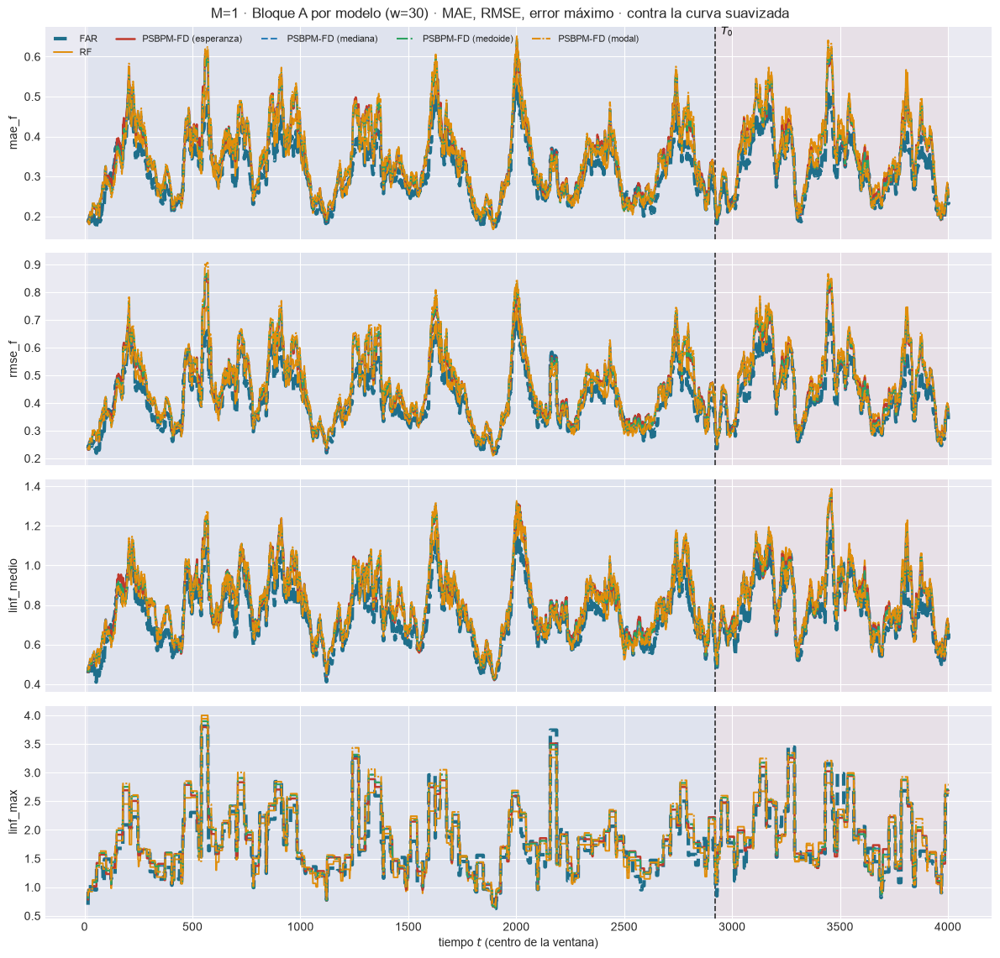

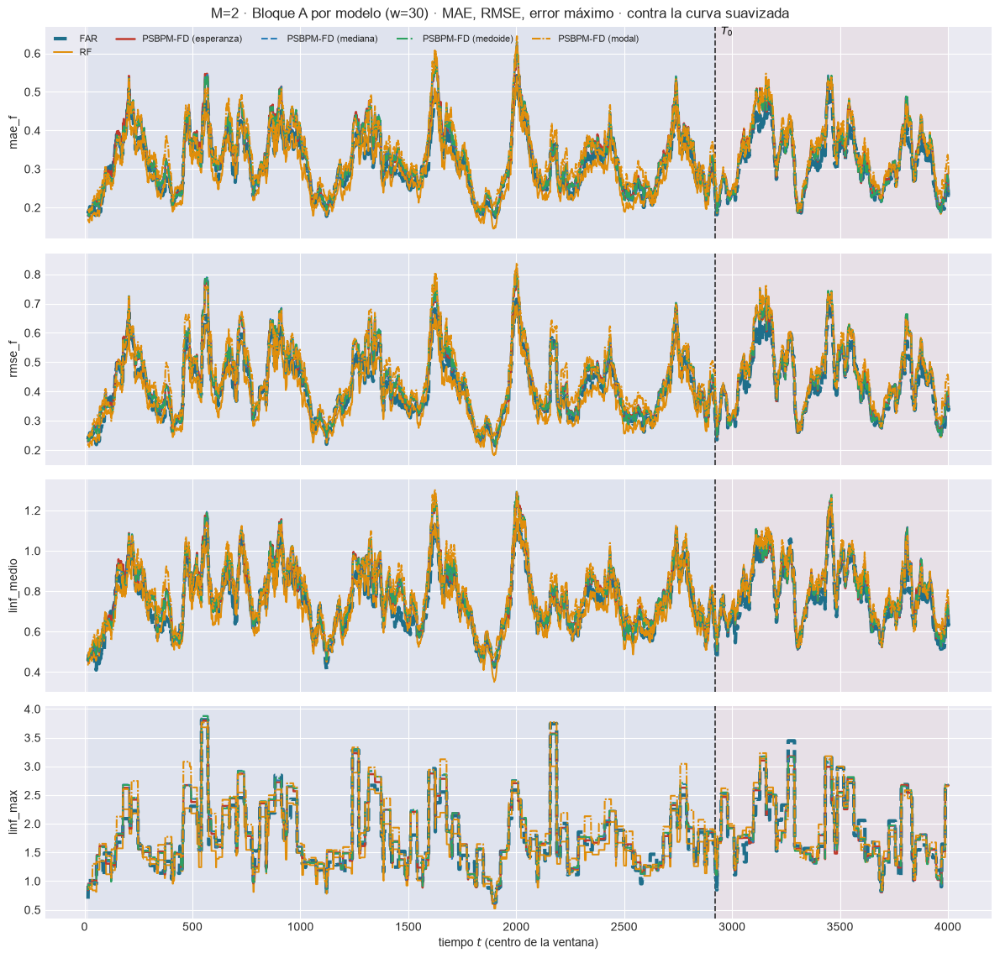

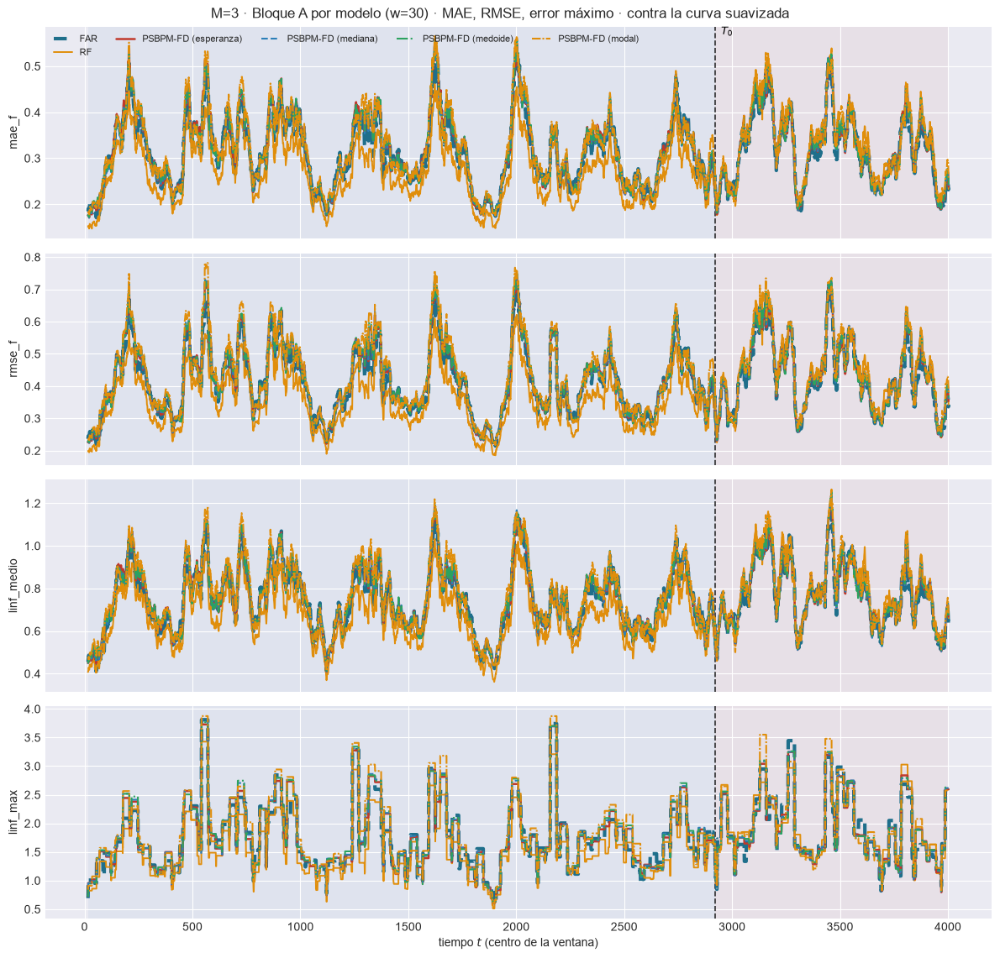

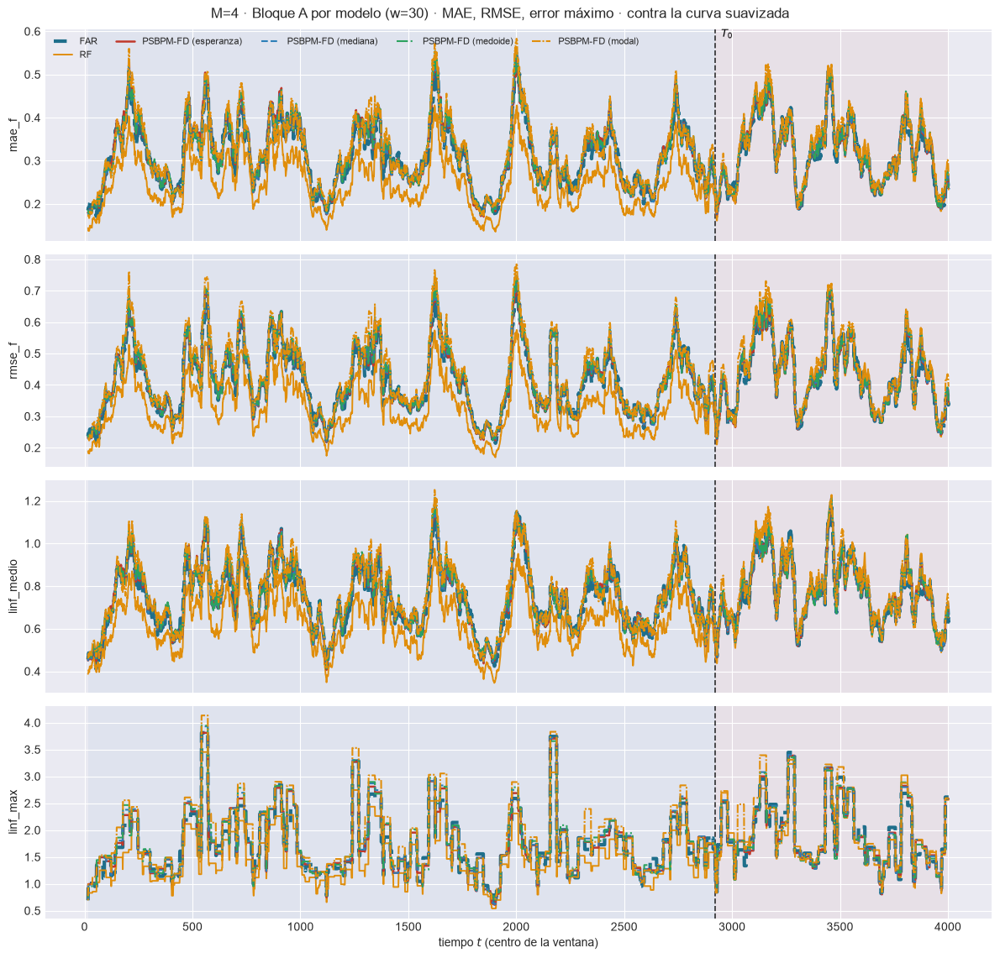

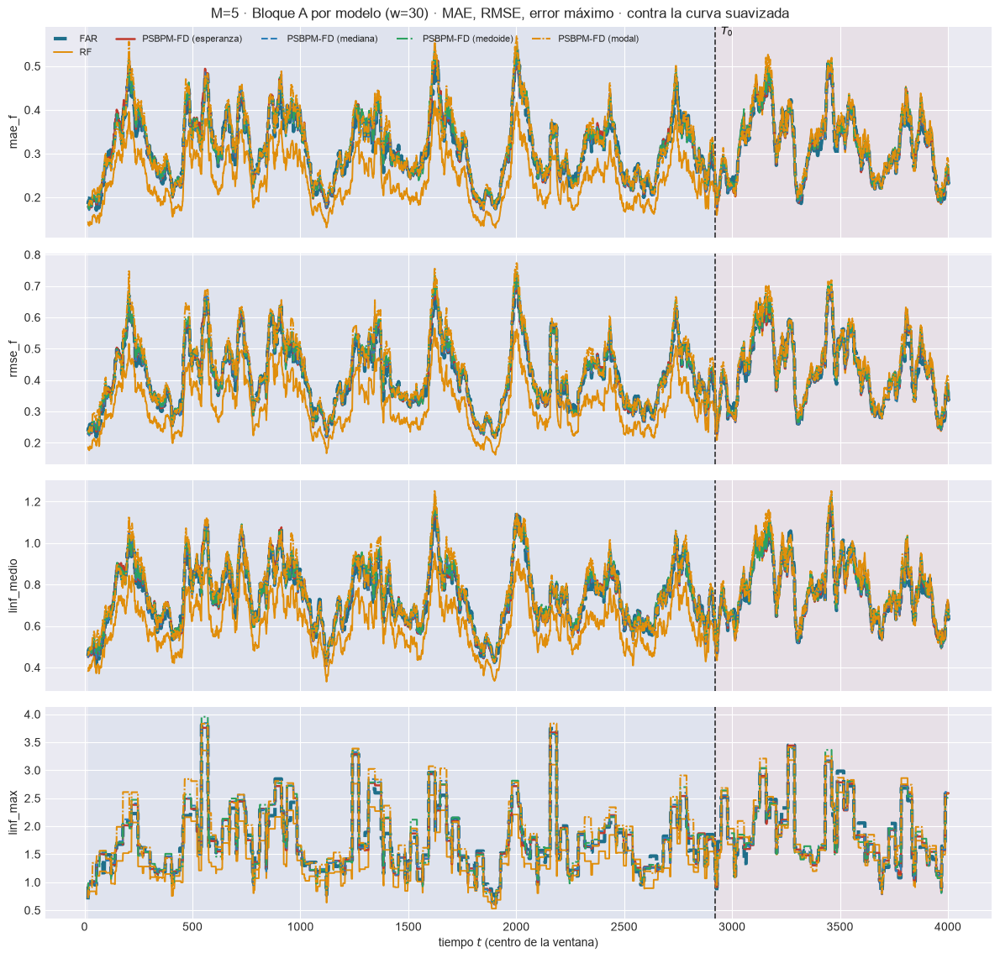

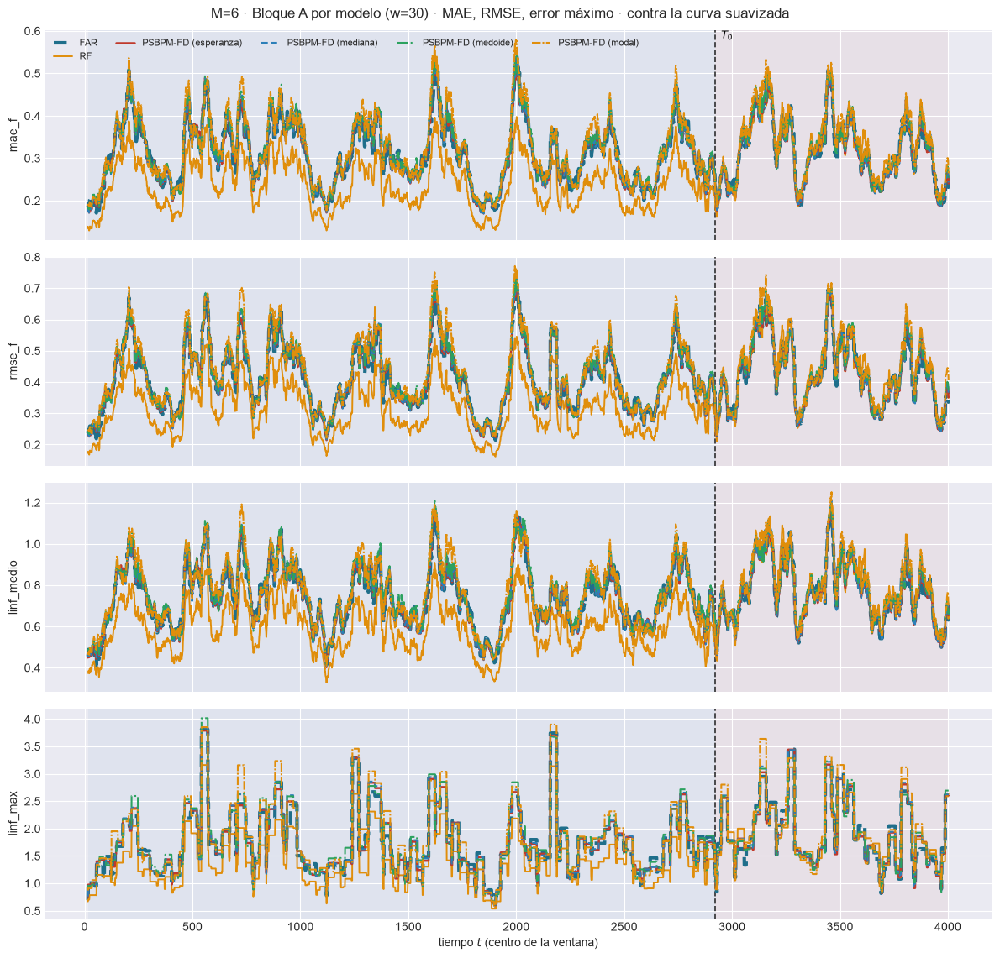

In [9]:
for M in M_OK:
    tablas_modelos(EST[M], DIS, ORIG, PESOS_TAU, PREFIJO)
verificar_cadena_modelos(EST, W_REF)

# Una figura por M; el piso de truncamiento va en las tablas pero no en la figura.
for M in M_OK:
    e = EST[M]
    tw = e["tablas_w"][W_REF]
    tf = tw[tw["modelo"] != PISO].copy()
    tf.attrs["w"] = W_REF
    plot_ventana_movil(
        tf, T0, METRICAS_A_COLS, columna_grupo="modelo", estilos=ESTILOS_MODELOS_PREDICTORES,
        title=f"M={M} · Bloque A por modelo (w={W_REF}) · MAE, RMSE, error máximo · contra la curva suavizada",
        save_path=str(e["paths"]["out_report"] / f"{PREFIJO + 8}_ventana_bloqueA_modelos_w{W_REF}.png"),
        verbose=False)
    plt.show()

## 5. Bloque B: intervalos, sólo FAR y PSBPM-FD (tres construcciones)

El RF no tiene mecanismo de intervalo propio. Del PSBPM-FD, equi-colas, simultánea y HDR con la esperanza, y el contraste misma predictiva, distinta construcción.

In [10]:
for M in M_OK:
    e = EST[M]
    construir_bandas(e, DIS, ORIG, IC_POR_TAU, IC_CORRECCION_ESTIMACION, IC_PSBP_TAMBIEN_GAUSSIANA,
                     intervalos_psbp=INTERVALOS)
    B_df = tabla_bloque_B(e, DIS, ORIG)
    display(B_df.loc["test"].style
            .format({"winkler": "{:.4f}", "picp": "{:.4f}", "ee_picp": "{:.4f}", "ace": "{:+.4f}",
                     "mpiw": "{:.4f}", "picp_simultaneo": "{:.4f}"})
            .background_gradient(subset=["winkler"], cmap="RdYlGn_r")
            .set_caption(f"M={M} · Bloque B, bloque de PRUEBA · PRIMARIA: winkler · nivel nominal {NIVEL:.0%}"))

M=1  kn=10  correccion=1.0017  sigma_eps(tau) del FAR: min=0.3048 max=0.5921 (razon 1.94)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = -0.0525   región de máxima densidad - equi-colas = -0.0431
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.0832   región de máxima densidad - equi-colas = +0.0124


M=2  kn=10  correccion=1.0017  sigma_eps(tau) del FAR: min=0.3048 max=0.5921 (razon 1.94)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = -0.0819   región de máxima densidad - equi-colas = +0.0172
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.0914   región de máxima densidad - equi-colas = +0.0223


M=3  kn=10  correccion=1.0017  sigma_eps(tau) del FAR: min=0.3048 max=0.5921 (razon 1.94)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.0090   región de máxima densidad - equi-colas = +0.0344
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.1386   región de máxima densidad - equi-colas = +0.0279


M=4  kn=10  correccion=1.0017  sigma_eps(tau) del FAR: min=0.3048 max=0.5921 (razon 1.94)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.0945   región de máxima densidad - equi-colas = +0.0344
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.2005   región de máxima densidad - equi-colas = +0.0390


M=5  kn=10  correccion=1.0017  sigma_eps(tau) del FAR: min=0.3048 max=0.5921 (razon 1.94)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.1487   región de máxima densidad - equi-colas = +0.0251
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.2252   región de máxima densidad - equi-colas = +0.0281


M=6  kn=10  correccion=1.0017  sigma_eps(tau) del FAR: min=0.3048 max=0.5921 (razon 1.94)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.1862   región de máxima densidad - equi-colas = +0.0283
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.2392   región de máxima densidad - equi-colas = +0.0281


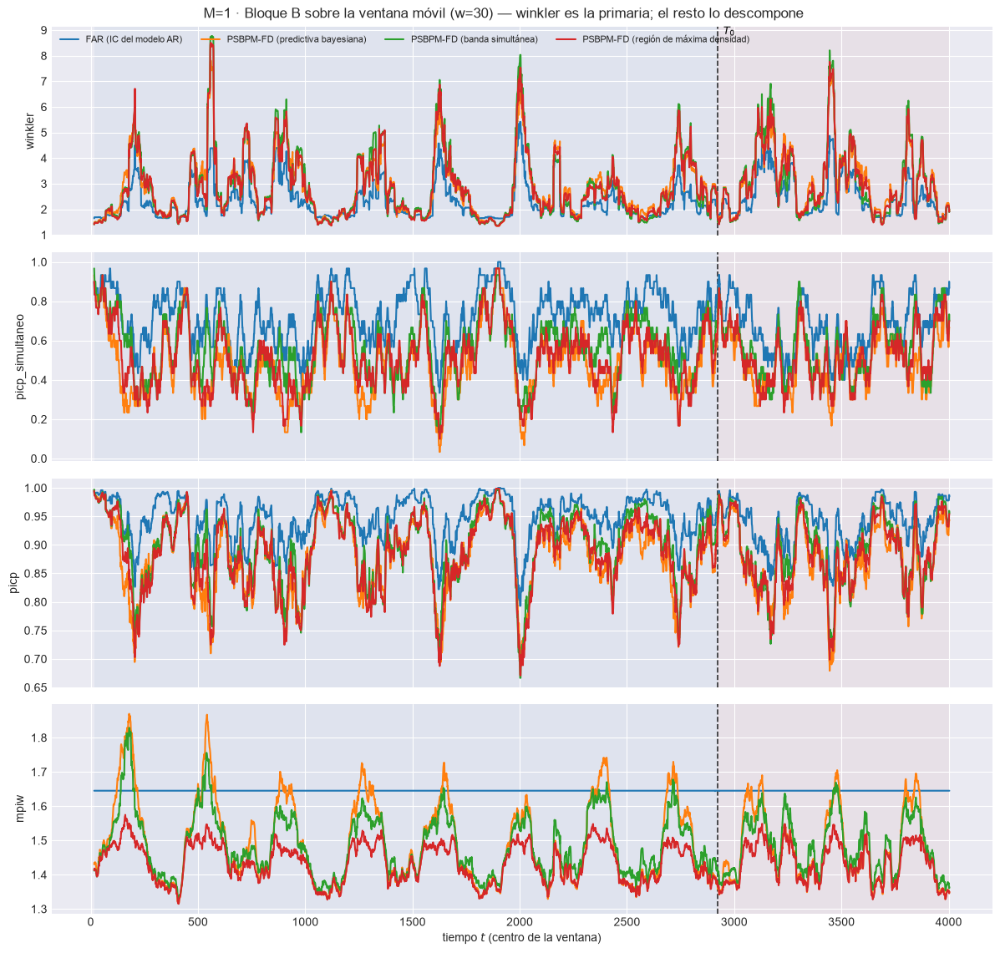

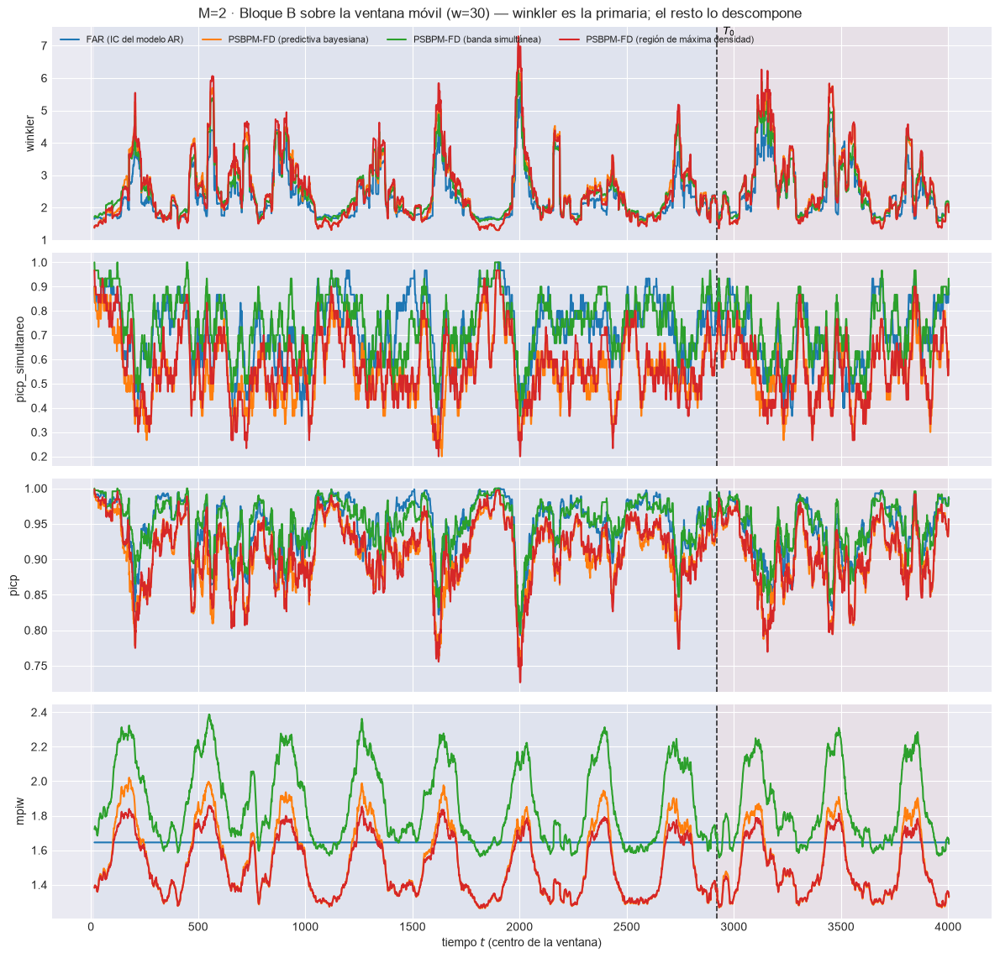

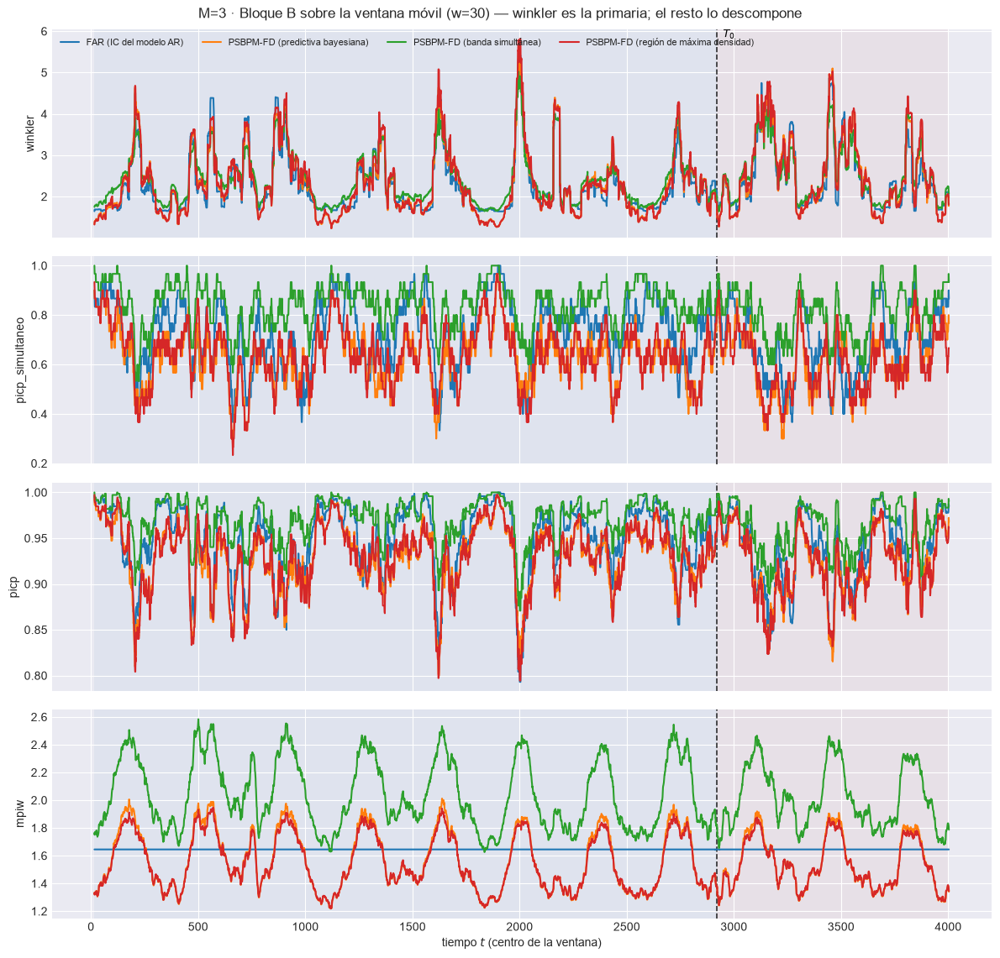

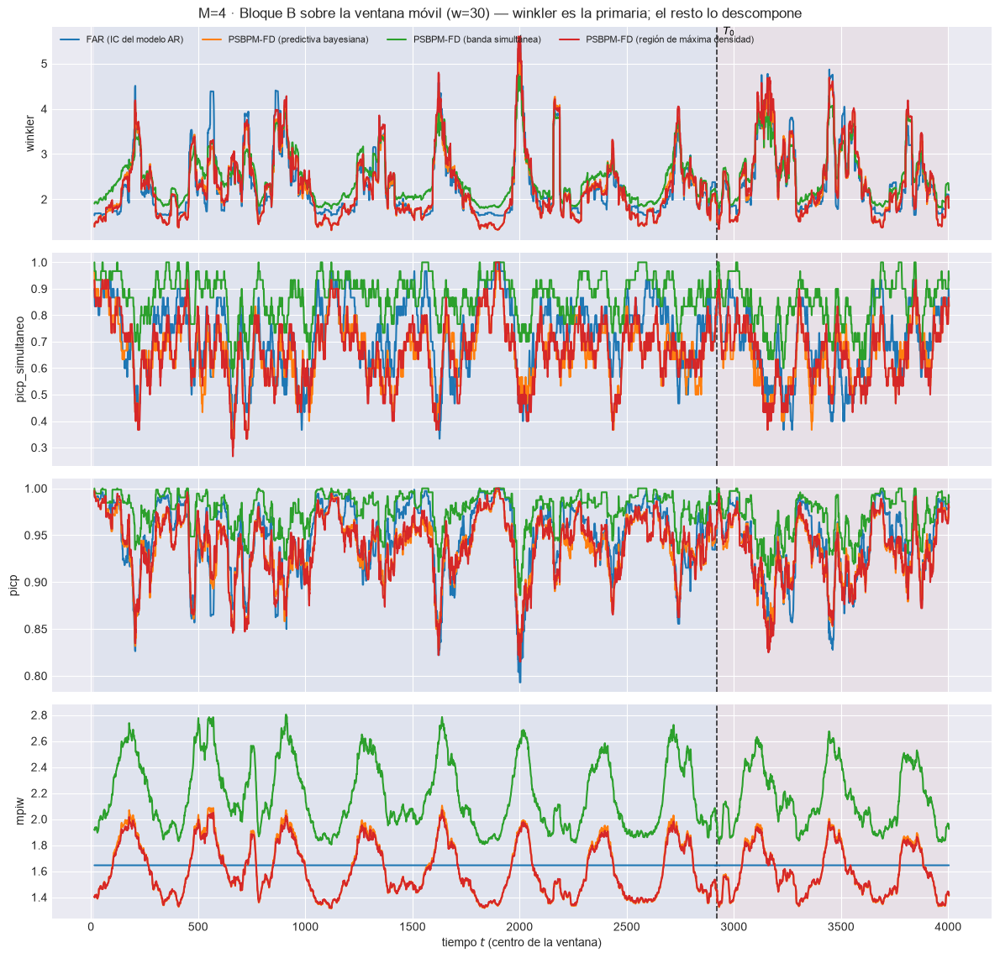

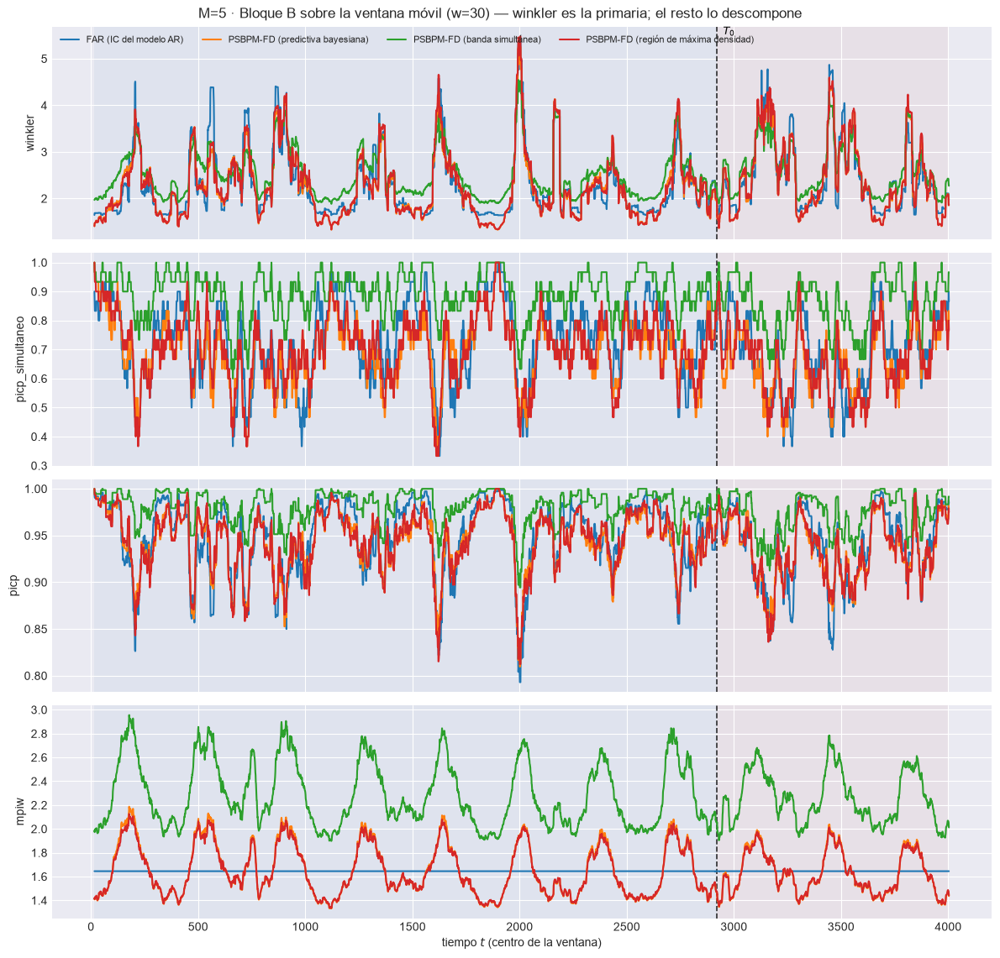

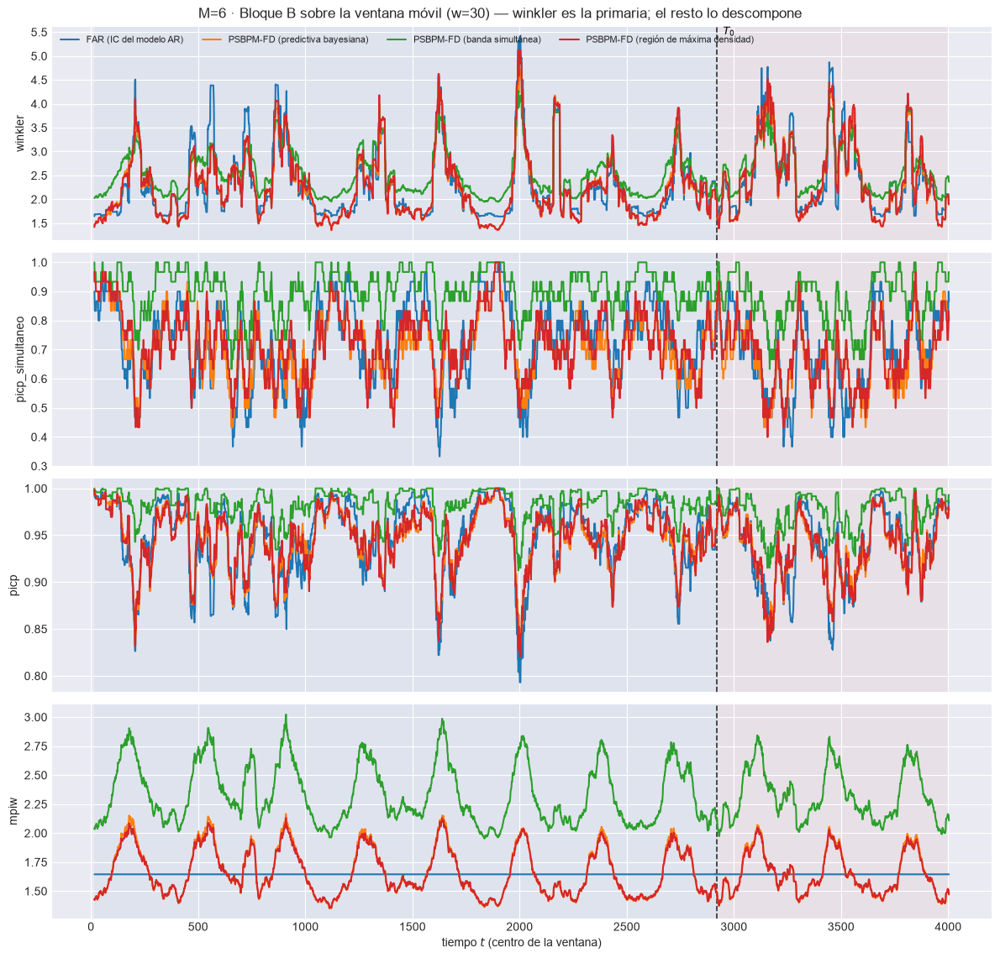

In [11]:
# Winkler sobre la ventana móvil y su descomposición: dice CUÁNDO falla la banda, no sólo cuánto.
for M in M_OK:
    e = EST[M]
    vb = ventana_bloque_B(e, DIS, ORIG, PESOS_TAU, PREFIJO)
    plot_ventana_movil(
        vb, T0, ["winkler", "picp_simultaneo", "picp", "mpiw"], columna_grupo="banda",
        title=f"M={M} · Bloque B sobre la ventana móvil (w={W_REF}) — winkler es la primaria; el resto lo descompone",
        save_path=str(e["paths"]["out_report"] / f"81_ventana_bloqueB_w{W_REF}.png"), verbose=False)
    plt.show()

## 6. Bloque A: quién gana cada ventana, y por cuánto

% de ventanas ganadas y razón contra el mejor y contra el FAR, sin las ventanas que cruzan $T_0$.

M,1,2,3,4,5,6
modelo,,,,,,
FAR,86.4%,72.3%,54.3%,48.3%,41.6%,37.1%
PSBPM-FD (esperanza),1.3%,1.8%,8.8%,14.4%,16.2%,19.9%
PSBPM-FD (mediana),4.7%,14.4%,8.8%,9.1%,15.1%,18.2%
PSBPM-FD (medoide),2.2%,8.0%,8.0%,7.0%,3.1%,3.9%
PSBPM-FD (modal),4.7%,1.3%,9.7%,8.6%,7.9%,2.6%
RF,0.7%,2.2%,10.4%,12.6%,16.1%,18.3%


M,1,2,3,4,5,6
modelo,,,,,,
FAR,1.005,1.009,1.017,1.019,1.020,1.023
PSBPM-FD (esperanza),1.105,1.057,1.032,1.024,1.023,1.020
PSBPM-FD (mediana),1.098,1.055,1.031,1.025,1.022,1.021
PSBPM-FD (medoide),1.098,1.055,1.034,1.031,1.038,1.040
PSBPM-FD (modal),1.106,1.094,1.058,1.057,1.050,1.062
RF,1.147,1.082,1.058,1.045,1.041,1.044


M,1,2,3,4,5,6
modelo,,,,,,
FAR,83.1%,70.3%,56.9%,49.0%,45.8%,39.7%
PSBPM-FD (esperanza),1.3%,2.7%,8.6%,13.8%,15.6%,21.6%
PSBPM-FD (mediana),4.2%,10.4%,8.0%,10.1%,9.9%,14.6%
PSBPM-FD (medoide),2.1%,9.4%,8.6%,8.2%,6.9%,3.9%
PSBPM-FD (modal),7.8%,1.7%,5.9%,3.0%,4.2%,2.9%
RF,1.5%,5.5%,12.0%,15.8%,17.5%,17.2%


M,1,2,3,4,5,6
modelo,,,,,,
FAR,1.005,1.009,1.015,1.018,1.018,1.020
PSBPM-FD (esperanza),1.102,1.053,1.031,1.024,1.022,1.020
PSBPM-FD (mediana),1.098,1.053,1.033,1.027,1.024,1.023
PSBPM-FD (medoide),1.098,1.054,1.035,1.032,1.036,1.039
PSBPM-FD (modal),1.104,1.090,1.060,1.069,1.055,1.065
RF,1.135,1.073,1.056,1.043,1.042,1.047


M,1,2,3,4,5,6
modelo,,,,,,
FAR,80.2%,73.0%,52.4%,41.1%,43.3%,36.9%
PSBPM-FD (esperanza),3.7%,7.6%,10.5%,9.9%,15.0%,17.4%
PSBPM-FD (mediana),3.7%,6.2%,9.6%,11.8%,11.0%,20.9%
PSBPM-FD (medoide),3.1%,6.2%,7.4%,15.6%,7.2%,4.7%
PSBPM-FD (modal),7.1%,4.9%,9.7%,6.8%,8.0%,2.8%
RF,2.2%,2.2%,10.5%,14.7%,15.6%,17.2%


M,1,2,3,4,5,6
modelo,,,,,,
FAR,1.005,1.008,1.015,1.019,1.018,1.018
PSBPM-FD (esperanza),1.078,1.046,1.023,1.020,1.018,1.016
PSBPM-FD (mediana),1.073,1.044,1.023,1.021,1.019,1.017
PSBPM-FD (medoide),1.073,1.045,1.025,1.024,1.031,1.037
PSBPM-FD (modal),1.074,1.066,1.042,1.046,1.042,1.050
RF,1.103,1.063,1.046,1.039,1.037,1.040


M,1,2,3,4,5,6
modelo,,,,,,
FAR,48.5%,44.0%,34.1%,32.6%,29.6%,25.6%
PSBPM-FD (esperanza),14.6%,14.6%,8.2%,4.6%,7.4%,9.7%
PSBPM-FD (mediana),1.1%,9.7%,2.1%,5.8%,3.7%,1.0%
PSBPM-FD (medoide),1.0%,6.6%,4.5%,13.3%,13.3%,12.8%
PSBPM-FD (modal),10.1%,11.7%,26.4%,17.6%,21.3%,18.4%
RF,24.6%,13.5%,24.6%,26.1%,24.7%,32.5%


M,1,2,3,4,5,6
modelo,,,,,,
FAR,1.056,1.063,1.060,1.053,1.058,1.056
PSBPM-FD (esperanza),1.086,1.058,1.058,1.051,1.054,1.056
PSBPM-FD (mediana),1.088,1.063,1.058,1.055,1.058,1.060
PSBPM-FD (medoide),1.088,1.064,1.059,1.053,1.065,1.062
PSBPM-FD (modal),1.097,1.098,1.081,1.088,1.083,1.094
RF,1.088,1.077,1.078,1.064,1.062,1.069


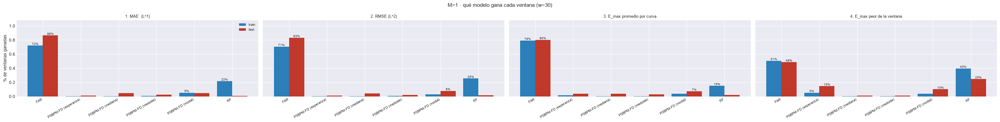

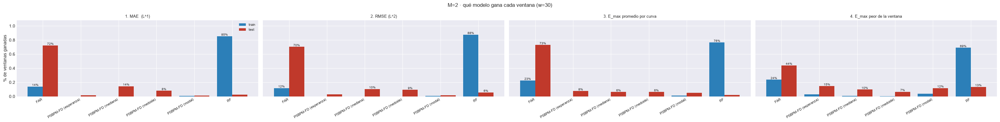

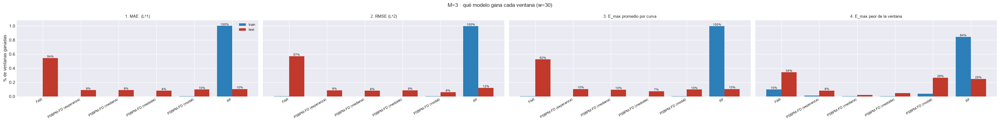

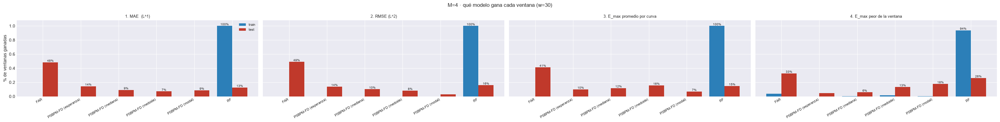

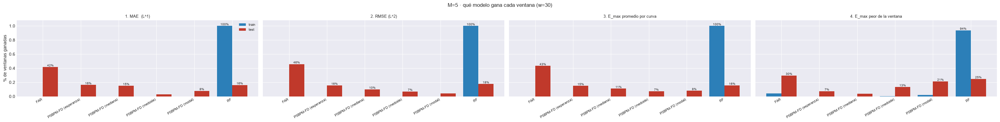

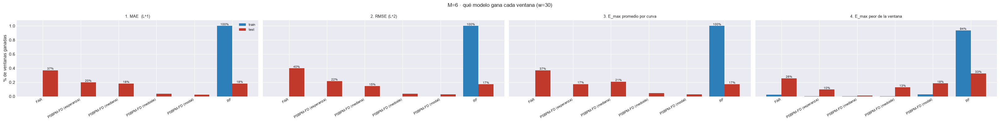

In [12]:
gana_A, rel_A = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO,))
gana_A.to_csv(PATH_BARRIDO / "96_ganador_ventana_bloqueA.csv", index=False)
rel_A.to_csv(PATH_BARRIDO / "96_razones_bloqueA.csv", index=False)

for etiqueta, _col in METRICAS_A:
    for tabla, v, fmt, cmap, cap in (
            (gana_A, "pct_ventanas_ganadas", "{:.1%}", "RdYlGn",
             f"{etiqueta} · % de ventanas de PRUEBA ganadas (w={W_REF}, sin cruzar T0)"),
            (rel_A, "razon_vs_mejor", "{:.3f}", "RdYlGn_r",
             f"{etiqueta} · razón contra el MEJOR de cada ventana (test) · 1.000 = gana siempre")):
        piv = (tabla[(tabla.metrica == etiqueta) & (tabla.bloque == "test")]
               .pivot(index="modelo", columns="M", values=v))
        display(piv.style.format(fmt, na_rep="-").background_gradient(cmap=cmap, axis=None).set_caption(cap))

for M in M_OK:
    plot_ganador_modelo(gana_A, M, METRICAS_A, W_REF,
                        EST[M]["paths"]["out_report"] / f"{PREFIJO + 8}_ganador_ventana_bloqueA.png")
    plt.show()

In [13]:
# Cada predictor del PSBPM-FD contra FAR y RF por separado (106_ganador_psbp_por_predictor.csv).
partes = []
for p in PREDICTORES:
    otros = [nombre_psbp(q) for q in PREDICTORES if q != p]
    g, _ = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO, *otros))
    partes.append(g[g.modelo == nombre_psbp(p)].assign(predictor=p))
gana_P = pd.concat(partes, ignore_index=True)
gana_P.to_csv(PATH_BARRIDO / "106_ganador_psbp_por_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(gana_P[(gana_P.metrica == etiqueta) & (gana_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST que gana el PSBPM-FD con cada predictor, contra FAR y RF"))

M,1,2,3,4,5,6
predictor,,,,,,
esperanza,8.1%,20.6%,28.3%,31.5%,35.1%,41.4%
mediana,11.1%,23.2%,31.1%,32.9%,37.1%,42.0%
medoide,11.0%,23.8%,28.7%,25.8%,19.5%,18.5%
modal,9.5%,5.0%,17.5%,16.5%,17.9%,12.1%


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,8.6%,19.4%,27.6%,31.4%,33.6%,41.4%
mediana,11.9%,22.2%,28.3%,31.8%,33.5%,38.6%
medoide,11.9%,21.6%,26.4%,26.3%,18.8%,20.8%
modal,12.7%,6.7%,15.1%,11.4%,15.7%,14.3%


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,10.7%,19.3%,27.8%,32.4%,33.9%,41.6%
mediana,14.2%,18.7%,29.3%,32.0%,32.8%,41.2%
medoide,14.2%,18.1%,25.6%,30.9%,22.7%,17.4%
modal,14.5%,9.8%,16.3%,18.7%,18.7%,9.4%


M,1,2,3,4,5,6
predictor,,,,,,
esperanza,20.1%,34.9%,25.8%,23.6%,24.4%,28.3%
mediana,16.9%,34.6%,25.6%,22.6%,20.9%,24.7%
medoide,16.9%,33.9%,22.8%,24.1%,21.2%,26.2%
modal,16.9%,23.0%,29.8%,24.6%,29.3%,25.2%


## 7. Bloque B: quién gana cada ventana, y por cuánto

Lo mismo sobre las bandas; el Winkler decide.

In [14]:
# En picp / picp_simultaneo "ganar" es estar más cerca del nominal, no tener el valor más bajo.
gana_B, rel_B = ganadores_por_ventana(EST, "ventana_B", "banda", METRICAS_B, NIVEL)
gana_B.to_csv(PATH_BARRIDO / "97_ganador_ventana_bloqueB.csv", index=False)
rel_B.to_csv(PATH_BARRIDO / "97_razones_bloqueB.csv", index=False)

for etiqueta, col in METRICAS_B:
    piv = (gana_B[(gana_B.metrica == etiqueta) & (gana_B.bloque == "test")]
           .pivot(index="banda", columns="M", values="pct_ventanas_ganadas"))
    crit = "más cerca del nominal" if col.startswith("picp") else "menor es mejor"
    display(piv.style.format("{:.1%}", na_rep="-").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas de PRUEBA ganadas (criterio: {crit})"))

M,1,2,3,4,5,6
banda,,,,,,
FAR (IC del modelo AR),0.0%,25.7%,30.1%,34.1%,39.1%,41.7%
PSBPM-FD (banda simultánea),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),11.9%,52.5%,52.5%,55.7%,56.8%,53.3%
PSBPM-FD (región de máxima densidad),88.1%,21.8%,17.4%,10.2%,4.1%,5.0%


M,1,2,3,4,5,6
banda,,,,,,
FAR (IC del modelo AR),73.1%,29.1%,21.2%,18.1%,19.9%,21.3%
PSBPM-FD (banda simultánea),7.1%,42.3%,44.1%,40.5%,37.2%,34.4%
PSBPM-FD (predictiva bayesiana),13.2%,18.6%,17.8%,26.1%,29.5%,29.2%
PSBPM-FD (región de máxima densidad),6.6%,10.0%,16.9%,15.4%,13.4%,15.1%


M,1,2,3,4,5,6
banda,,,,,,
FAR (IC del modelo AR),92.3%,36.7%,11.5%,7.9%,4.8%,3.6%
PSBPM-FD (banda simultánea),5.2%,63.3%,88.0%,90.8%,94.7%,95.5%
PSBPM-FD (predictiva bayesiana),2.4%,0.0%,0.5%,1.2%,0.2%,0.7%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.1%,0.4%,0.2%


M,1,2,3,4,5,6
banda,,,,,,
FAR (IC del modelo AR),81.6%,54.6%,47.8%,43.9%,41.8%,38.1%
PSBPM-FD (banda simultánea),14.7%,17.4%,21.1%,20.3%,22.8%,22.8%
PSBPM-FD (predictiva bayesiana),1.4%,6.8%,21.1%,19.5%,18.7%,31.5%
PSBPM-FD (región de máxima densidad),2.2%,21.1%,10.0%,16.3%,16.7%,7.6%


M,1,2,3,4,5,6
banda,,,,,,
FAR (IC del modelo AR),92.7%,45.5%,6.6%,4.5%,4.4%,2.0%
PSBPM-FD (banda simultánea),4.9%,53.9%,92.4%,93.8%,93.4%,94.4%
PSBPM-FD (predictiva bayesiana),2.4%,0.0%,0.1%,0.3%,1.0%,2.0%
PSBPM-FD (región de máxima densidad),0.0%,0.7%,0.9%,1.4%,1.1%,1.7%


M,1,2,3,4,5,6
banda,,,,,,
FAR (IC del modelo AR),74.2%,47.0%,20.1%,10.1%,4.1%,0.3%
PSBPM-FD (banda simultánea),6.0%,42.8%,78.7%,89.8%,95.2%,99.1%
PSBPM-FD (predictiva bayesiana),18.9%,10.2%,1.1%,0.1%,0.7%,0.6%
PSBPM-FD (región de máxima densidad),0.8%,0.0%,0.0%,0.0%,0.0%,0.1%


## 8. Cuadro resumen: mínimo, máximo y promedio

Por modelo, métrica y bloque, sin las ventanas que cruzan $T_0$.

In [15]:
resumen_A = resumen_min_max(EST, "ventana_df", "modelo", METRICAS_A, excluir=(PISO,))
resumen_B = resumen_min_max(EST, "ventana_B", "banda", METRICAS_B)
resumen_A.to_csv(PATH_BARRIDO / "98_resumen_bloqueA_min_max_prom.csv", index=False)
resumen_B.to_csv(PATH_BARRIDO / "99_resumen_bloqueB_min_max_prom.csv", index=False)

for M in M_OK:
    for res, grupo, fmt, nombre in ((resumen_A, "modelo", "{:.6f}", "Bloque A"), (resumen_B, "banda", "{:.4f}", "Bloque B")):
        sub = (res[(res.M == M) & (res.bloque == "test")]
               .set_index(["metrica", grupo])[["minimo", "maximo", "promedio"]])
        display(sub.style.format(fmt).background_gradient(subset=["maximo"], cmap="RdYlGn_r")
                .set_caption(f"M={M} · {nombre} en el TEST · mínimo / máximo / promedio sobre las ventanas (w={W_REF})"))

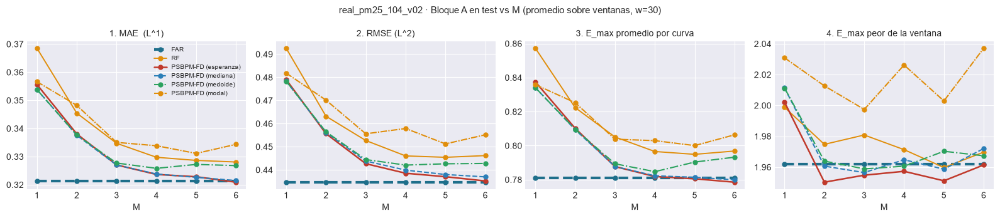

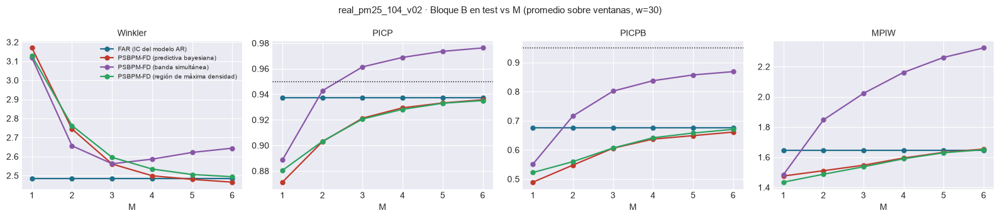

In [16]:
# Las métricas contra M: promedio en test sobre las ventanas, una línea por modelo / banda.
ESTILOS_BANDAS = {G_FAR: dict(color="#1f6f8b"), G_PSG: dict(color="#e08e0b"), G_PSB: dict(color="#c0392b"),
                  G_PSS: dict(color="#8856a7"), G_PSH: dict(color="#2ca25f")}

plot_metricas_vs_M(promedio_vs_M(resumen_A, "modelo"), METRICAS_A, ESTILOS_MODELOS_PREDICTORES,
                   f"{EXPERIMENT_BASE} · Bloque A en test vs M (promedio sobre ventanas, w={W_REF})",
                   save_path=PATH_BARRIDO / f"{PREFIJO + 6}_bloqueA_vs_M.png")
plt.show()
plot_metricas_vs_M(promedio_vs_M(resumen_B, "banda"),
                   [("Winkler", "winkler"), ("PICP", "picp"), ("PICPB", "picp_simultaneo"), ("MPIW", "mpiw")],
                   ESTILOS_BANDAS,
                   f"{EXPERIMENT_BASE} · Bloque B en test vs M (promedio sobre ventanas, w={W_REF})",
                   nominal=NIVEL, save_path=PATH_BARRIDO / f"{PREFIJO + 7}_bloqueB_vs_M.png")
plt.show()

### 8.1 Cada construcción del PSBPM-FD contra el FAR

Winkler medio en test menos el del FAR y % de ventanas ganadas cara a cara (`111_*`).

In [17]:
B_VS_FAR = bloqueB_contra_far(EST, PATH_BARRIDO)
display(B_VS_FAR.style.format(precision=4)
        .set_caption("Bloque B · construcciones del PSBPM-FD contra el FAR (test, w de referencia)"))

,M,banda,n_ventanas,winkler,winkler_FAR,dif_winkler_vs_FAR,pct_ventanas_gana_FAR
0,1,PSBPM-FD (banda simultánea),1067,3.1176,2.4837,0.6338,0.1649
1,1,PSBPM-FD (predictiva bayesiana),1067,3.1698,2.4837,0.6860,0.1218
2,1,PSBPM-FD (región de máxima densidad),1067,3.1272,2.4837,0.6435,0.1359
3,2,PSBPM-FD (banda simultánea),1067,2.6563,2.4837,0.1725,0.3618
4,2,PSBPM-FD (predictiva bayesiana),1067,2.7444,2.4837,0.2607,0.3346
5,2,PSBPM-FD (región de máxima densidad),1067,2.7621,2.4837,0.2784,0.3383
6,3,PSBPM-FD (banda simultánea),1067,2.5622,2.4837,0.0785,0.2718
7,3,PSBPM-FD (predictiva bayesiana),1067,2.5608,2.4837,0.0770,0.3889
8,3,PSBPM-FD (región de máxima densidad),1067,2.5957,2.4837,0.1120,0.3636
9,4,PSBPM-FD (banda simultánea),1067,2.5862,2.4837,0.1025,0.2549


## 9. Intervalos de credibilidad: FAR contra PSBPM-FD, en la ventana de detalle

Tres figuras por $M$ (FAR contra equi-colas, HDR y simultánea) y la tabla de ancho y cobertura por origen, con la cobertura de curva completa como cuenta. En la 28 el PSBPM-FD alcanzaba al FAR en el Bloque A en $M = 6$ (MAE 0.321 contra 0.321) y le ganaba el Winkler sólo desde $M = 5$ (2.48 contra 2.48 en $M = 5$, 2.47 en $M = 6$), con PICPB 0.66 contra 0.68: la ventaja esperable de una serie tipo GARCH está en el Bloque B. Es aquí donde se ve si la banda del PSBPM-FD se ensancha en los episodios de invierno y se angosta fuera de ellos, mientras la del FAR tiene el mismo ancho en todo origen.

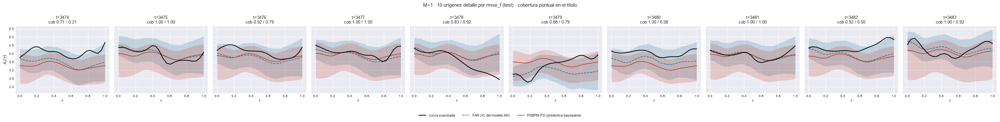

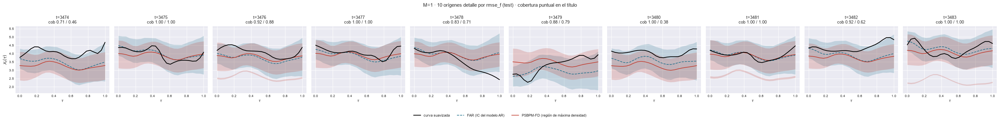

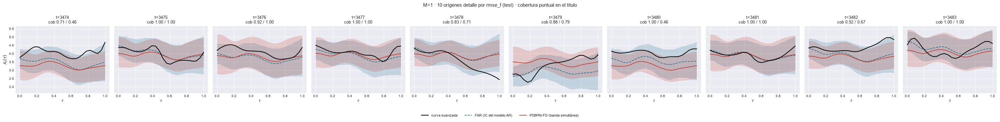

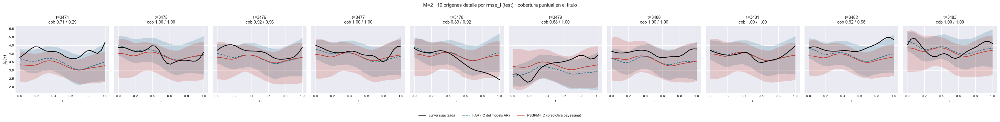

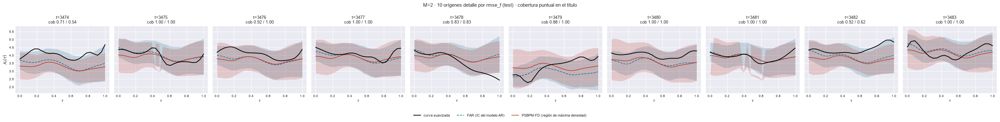

...

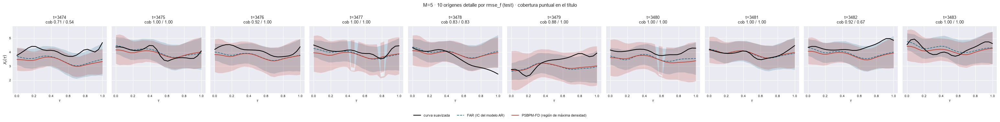

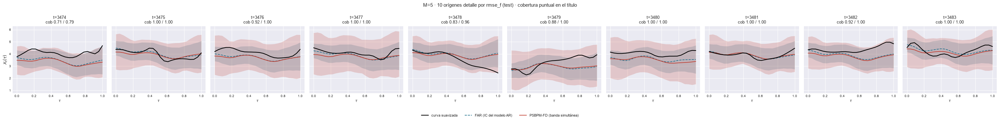

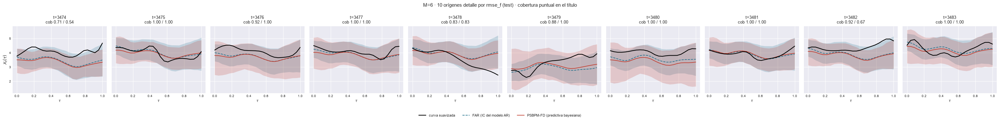

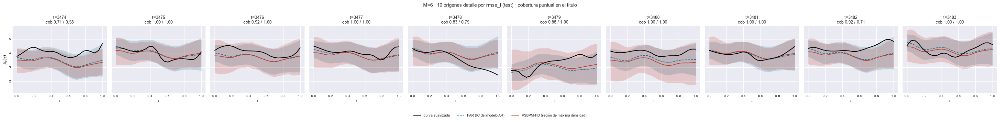

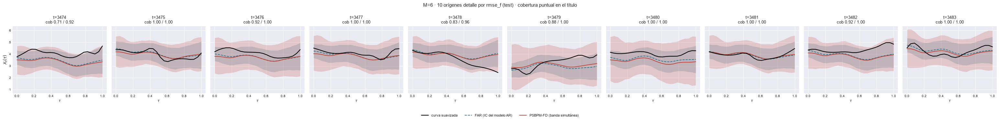

In [18]:
M_9 = M_OK if M_DETALLE is None else tuple(m for m in M_DETALLE if m in M_OK)
DETALLE = {"detalle": IDX_DET}
for M in M_9:
    for par, sufijo in ((BANDA_A_CONTRASTAR, ""), (("FAR", G_PSH), "_hdr"), (("FAR", G_PSS), "_simultanea")):
        plot_bandas_contraste(
            EST[M]["BANDAS"], DETALLE, X_obj_ev, grilla, t_orig, M, METRICA_SEL_IC, par, "detalle",
            EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_detalle{sufijo}.png")
        plt.show()

In [19]:
# Ancho y cobertura por origen de cada banda en la ventana de detalle (79_ic_contraste_origenes.csv por M).
filas = []
for M in M_9:
    for i in IDX_DET:
        for nombre, ((L, U), _Xp) in EST[M]["BANDAS"].items():
            dentro = cobertura_tramos(X_obj_ev[i], L[i], U[i])
            filas.append({"M": M, "t": int(t_orig[i]), "banda": nombre,
                          "mpiw": float(ancho_tramos(L[i], U[i]).mean()),
                          "picp_puntual": float(dentro.mean()), "I_t_simultaneo": float(dentro.all())})
ic_df = pd.DataFrame(filas)
for M in M_9:
    ic_df[ic_df.M == M].drop(columns="M").to_csv(
        EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_origenes.csv", index=False)
display(ic_df.groupby(["M", "banda"]).agg(mpiw=("mpiw", "mean"), picp_puntual=("picp_puntual", "mean"),
                                          curvas_cubiertas=("I_t_simultaneo", "sum"))
        .style.format({"mpiw": "{:.3f}", "picp_puntual": "{:.3f}", "curvas_cubiertas": "{:.0f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..): curvas_cubiertas = cuántas de las {N_DETALLE} "
                     "quedan enteras dentro de la banda (descriptivo)"))
print("Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO")
print("depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes")
print("es la flexibilidad de una predictiva que depende del estado.")

Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO
depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes
es la flexibilidad de una predictiva que depende del estado.


## 10. Comportamientos predictivos contra lo observado

Sobre todo el test y, aparte, sobre la ventana de detalle (cuentas): comportamiento en que cae lo observado, su probabilidad y si es el más probable; error en el origen de la curva típica del realizado (cota) y del más probable (pronóstico) frente a la esperanza, el FAR y el RF; cobertura, ancho y Winkler de la banda del realizado, del más probable y de la marginal. Todos los orígenes y sólo $K \ge 2$, contra los dos objetivos.

In [20]:
# validar_observado sobre TODO el bloque de prueba (las cifras del cuerpo) y, aparte, sobre la ventana de
# detalle (las cuentas de k de 10). La máscara de los comportamientos se restringe a cada subconjunto. Por
# subconjunto y objetivo, dos filas de resumen: todos los orígenes y sólo K >= 2 (donde el comportamiento
# realizado y el más probable se apartan de la marginal). Error en el origen de la curva típica (realizado =
# cota, más probable = pronóstico) y de las referencias puntuales: esperanza del PSBPM-FD, FAR y RF.
SUBCONJUNTOS = {"test": ~es_train, "detalle": MASK_DET}
partes, res = [], []
for M in M_OK:
    e = EST[M]
    C = cargar_comportamientos(e["paths"])
    assert C is not None and np.array_equal(C["t_orig"], t_orig), f"[M={M}] falta el §12 del _04."
    li_f, ls_f = e["BANDA_PSBP"]
    por_M = []
    for sub, mask in SUBCONJUNTOS.items():
        C["mascara"] = mask.copy()
        for objetivo, Y in (("curva_suavizada", X_obj_ev), ("representacion_fpca", e["X_proj"])):
            v = validar_observado(C, e["Y_obs"], Y, li_f, ls_f, grilla, PESOS_TAU,
                                  curvas_ref={"esperanza": e["X_PSBP"], "FAR": e["CURVAS"]["FAR"],
                                              "RF": e["CURVAS"]["RF"]})
            v.insert(0, "subconjunto", sub)
            v.insert(1, "objetivo", objetivo)
            v.insert(2, "t", t_orig[v["i"].to_numpy()])
            por_M.append(v)
            for grupo, g in (("todos", v), ("K>=2", v[v.K >= 2])):
                fila = {"M": M, "subconjunto": sub, "objetivo": objetivo, "origenes": grupo, "n": int(len(g))}
                if len(g):
                    fila.update({"K >= 2": int((g.K >= 2).sum()),
                                 "cae en el más probable": float(g.acierto.mean()),
                                 "p_obs media": float(g.p_obs.mean()), "p_esperada media": float(g.p_esperada.mean()),
                                 **{f"{m}_{k}": float(g[f"{m}_{k}"].mean()) for m in ("mae", "rmse")
                                    for k in ("real", "mp", "esperanza", "FAR", "RF")},
                                 "mp gana a FAR": float((g.mae_mp < g.mae_FAR).mean()),
                                 "mp gana a RF": float((g.mae_mp < g.mae_RF).mean()),
                                 "mp gana a esperanza": float((g.mae_mp < g.mae_esperanza).mean()),
                                 "curva entera en banda real": float(g.picpb_real.mean()),
                                 "curva entera en banda mp": float(g.picpb_mp.mean()),
                                 "curva entera en banda marginal": float(g.picpb_marg.mean()),
                                 "mpiw_real": float(g.mpiw_real.mean()), "mpiw_mp": float(g.mpiw_mp.mean()),
                                 "mpiw_marg": float(g.mpiw_marg.mean()), "winkler_real": float(g.winkler_real.mean()),
                                 "winkler_mp": float(g.winkler_mp.mean()), "winkler_marg": float(g.winkler_marg.mean())})
                res.append(fila)
    pd.concat(por_M, ignore_index=True).to_csv(e["paths"]["out_report"] / "82_validacion_comportamientos.csv",
                                              index=False)
    pd.DataFrame([r for r in res if r["M"] == M]).to_csv(e["paths"]["out_report"] / "83_validacion_resumen.csv",
                                                         index=False)
VAL_COMP = pd.DataFrame(res).assign(t0_detalle=T0_DET)
VAL_COMP.to_csv(PATH_BARRIDO / "105_validacion_comportamientos_por_M.csv", index=False)
COLS = ["n", "K >= 2", "cae en el más probable", "mae_mp", "mae_real", "mae_esperanza", "mae_FAR", "mae_RF",
        "mp gana a FAR", "mp gana a RF", "mp gana a esperanza", "curva entera en banda marginal"]
for sub, nota in (("test", "fracciones sobre todo el bloque de prueba"),
                  ("detalle", f"ventana de detalle t={T0_DET}..{T0_DET + N_DETALLE - 1}: fracciones de {N_DETALLE} orígenes")):
    display(VAL_COMP[(VAL_COMP.subconjunto == sub) & (VAL_COMP.objetivo == "curva_suavizada")]
            .set_index(["M", "origenes"])[COLS].style.format(precision=3)
            .set_caption(f"Comportamientos contra lo observado · {nota} · objetivo = curva suavizada"))
